# T1-4: Pure Strain / Hyperbolic Flow (2D)

## Verification Study — Tier 1 / Trivial Trajectories

**Field:** $u = \varepsilon\,x$, $v = -\varepsilon\,y$

**Analytical trajectory:**
$$x(t) = x_0\,e^{\varepsilon t}, \quad y(t) = y_0\,e^{-\varepsilon t}$$

**Purpose:** First test with exponential divergence of nearby trajectories; stress-tests
time integrator accuracy near the stagnation point (origin). Error amplification is expected
— the exponential growth magnifies any truncation error.

**Expected convergence:** Order $p$ (integrator order) in $\Delta t$ for node-centered grids
(exact interpolation of the linear field).

**Notes:**
- Particles near the stagnation point (small $x_0$, $y_0$) remain nearly stationary
- Particles far from the origin experience rapid stretching along $x$ and compression along $y$
- The flow conserves area: $\nabla \cdot \mathbf{u} = \varepsilon - \varepsilon = 0$
- Trajectories follow hyperbolas $x \cdot y = x_0 \cdot y_0 = \text{const}$

---

### Approach

We construct a Delaunay triangulation over a square domain centered at the origin and define
a pure strain velocity field. Particles are placed both near and far from the stagnation point
to test the full range of behavior. We sweep interpolator / time integrator combinations
and verify against the analytical exponential trajectories.

In [1]:
import math
import os
import shutil

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32 (~1e-6 deg resolution);
# use float64 positions so the error tolerances below are meaningful.
Particle64 = get_default_particle(np.float64)

## 1. Parameters

In [2]:
# Domain (centered at origin = stagnation point)
NX = 40
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

# Strain rate
EPSILON = 1e-3  # s^{-1}

# Time — must be divisible by all DT_VALUES in the convergence study,
# and short enough that all particles stay inside the domain.
# x(T) = x0 * exp(eps*T). For x0=3, T=360: x(T) = 3*exp(0.36) ~ 4.30
# LCM(120,60,30,15,5) = 120; 360 = 3*120.
T_TOTAL_S = 360.0
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_BASE = np.timedelta64(30, "s")

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particle initial positions:
# - Near stagnation point (small displacements from origin)
# - Moderate distance
# - Far from origin (will experience strong stretching)
p_coords_near = [
    (0.1, 0.1), (-0.1, 0.1), (0.1, -0.1), (-0.1, -0.1),
    (0.05, 0.2), (0.2, 0.05),
]
p_coords_mid = [
    (1.0, 1.0), (-1.0, 1.0), (1.0, -1.0), (-1.0, -1.0),
    (0.5, 2.0), (2.0, 0.5),
]
p_coords_far = [
    (3.0, 1.0), (-3.0, 1.0), (1.0, 3.0), (1.0, -3.0),
    (2.5, 2.5), (-2.5, -2.5),
]

all_coords = p_coords_near + p_coords_mid + p_coords_far
p_lon0 = np.array([c[0] for c in all_coords], dtype=np.float64)
p_lat0 = np.array([c[1] for c in all_coords], dtype=np.float64)
N_PARTICLES = len(p_lon0)

# Labels for particle groups
n_near = len(p_coords_near)
n_mid = len(p_coords_mid)
n_far = len(p_coords_far)
particle_group = (
    ["near"] * n_near + ["mid"] * n_mid + ["far"] * n_far
)

print(f"\u03b5 = {EPSILON:.1e} s^-1")
print(f"Total runtime = {T_TOTAL_S:.0f} s")
print(f"exp(\u03b5*T) = {np.exp(EPSILON * T_TOTAL_S):.4f}")
print(f"{N_PARTICLES} particles: {n_near} near, {n_mid} mid, {n_far} far")

ε = 1.0e-03 s^-1
Total runtime = 360 s
exp(ε*T) = 1.4333
18 particles: 6 near, 6 mid, 6 far


## 2. Build Unstructured Grid

In [3]:
lon, lat = np.meshgrid(
    np.linspace(LON_MIN, LON_MAX, NX, dtype=np.float64),
    np.linspace(LAT_MIN, LAT_MAX, NX, dtype=np.float64),
)
lon_flat = lon.ravel()
lat_flat = lat.ravel()

mask = (
    np.isclose(lon_flat, LON_MIN)
    | np.isclose(lon_flat, LON_MAX)
    | np.isclose(lat_flat, LAT_MIN)
    | np.isclose(lat_flat, LAT_MAX)
)
boundary_points = np.flatnonzero(mask)

uxgrid = ux.Grid.from_points(
    (lon_flat, lat_flat),
    method="regional_delaunay",
    boundary_points=boundary_points,
)
uxgrid.attrs["Conventions"] = "UGRID-1.0"

print(f"Grid: {uxgrid.n_node} nodes, {uxgrid.n_face} faces")

Grid: 1600 nodes, 3039 faces


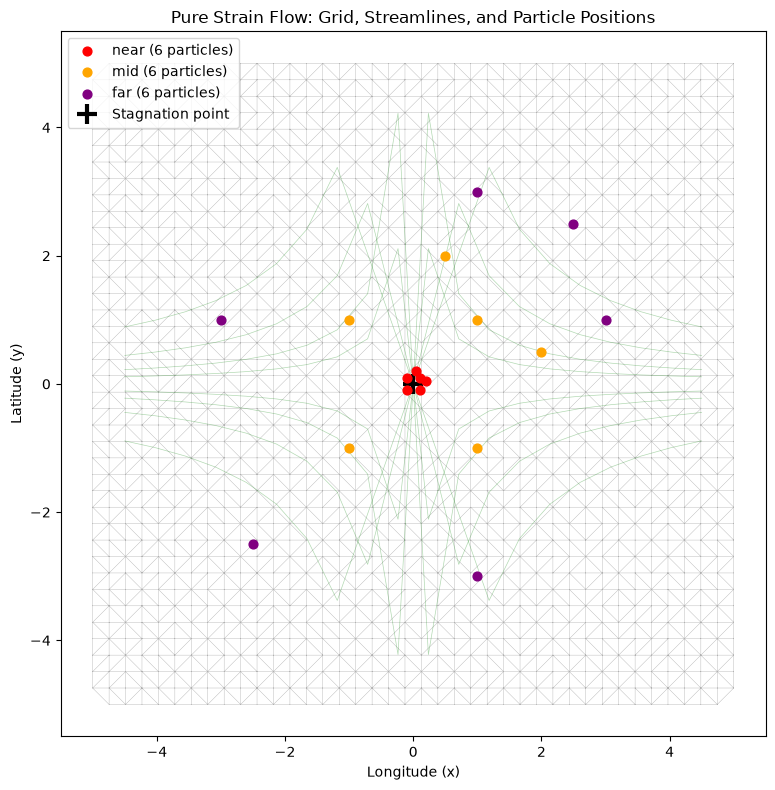

In [4]:
# Visualize grid, particle positions, and flow structure
fig, ax = plt.subplots(figsize=(8, 8))

triang = mtri.Triangulation(
    uxgrid.node_lon.values, uxgrid.node_lat.values,
    triangles=uxgrid.face_node_connectivity.values,
)
ax.triplot(triang, "k-", lw=0.3, alpha=0.3)

# Streamlines of the hyperbolic flow (xy = const)
x_stream = np.linspace(-4.5, 4.5, 20)
for c in [0.5, 1.0, 2.0, 4.0]:
    y_pos = c / x_stream
    y_neg = -c / x_stream
    valid = np.abs(y_pos) < HALF
    ax.plot(x_stream[valid], y_pos[valid], "g-", lw=0.5, alpha=0.3)
    ax.plot(x_stream[valid], y_neg[valid], "g-", lw=0.5, alpha=0.3)

# Color particles by group
colors_group = {"near": "red", "mid": "orange", "far": "purple"}
for group in ["near", "mid", "far"]:
    idx = [i for i, g in enumerate(particle_group) if g == group]
    ax.scatter(p_lon0[idx], p_lat0[idx], c=colors_group[group], s=40,
               zorder=5, label=f"{group} ({len(idx)} particles)")

ax.plot(0, 0, "k+", ms=15, mew=3, label="Stagnation point")
ax.set_xlabel("Longitude (x)")
ax.set_ylabel("Latitude (y)")
ax.set_title("Pure Strain Flow: Grid, Streamlines, and Particle Positions")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 3. Define Velocity Fields

Pure strain (hyperbolic) flow:
$$u = \varepsilon\,x, \quad v = -\varepsilon\,y$$

This is a linear field, so barycentric (node-centered) interpolation reproduces it exactly.
The flow is incompressible ($\nabla \cdot \mathbf{u} = 0$) and irrotational
($\nabla \times \mathbf{u} = 0$).

In [5]:
zf = np.array([0.0, 1.0], dtype=np.float64)
zc = np.array([0.5], dtype=np.float64)


def make_face_centered_dataset(uxgrid, epsilon):
    """Velocity on face centers: u = epsilon*x_face, v = -epsilon*y_face."""
    face_lon = uxgrid.face_lon.values
    face_lat = uxgrid.face_lat.values

    u_vals = epsilon * face_lon
    v_vals = -epsilon * face_lat

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (pure strain)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (pure strain)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def make_node_centered_dataset(uxgrid, epsilon):
    """Velocity on corner nodes: u = epsilon*x_node, v = -epsilon*y_node."""
    node_lon = uxgrid.node_lon.values
    node_lat = uxgrid.node_lat.values

    u_vals = epsilon * node_lon
    v_vals = -epsilon * node_lat

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (pure strain)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (pure strain)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


ds_face = make_face_centered_dataset(uxgrid, EPSILON)
ds_node = make_node_centered_dataset(uxgrid, EPSILON)

print("Face-centered dataset:")
print(ds_face)
print()
print("Node-centered dataset:")
print(ds_node)

Face-centered dataset:
<xarray.UxDataset> Size: 74kB
Dimensions:  (time: 1, zc: 1, n_face: 3039, zf: 2, n_node: 1600)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_face, n_node
Data variables:
    U        (time, zc, n_face) float64 24kB -0.004915 -0.004829 ... 0.001496
    V        (time, zc, n_face) float64 24kB 0.0004701 0.0005556 ... 0.002778
    W        (time, zf, n_node) float64 26kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

Node-centered dataset:
<xarray.UxDataset> Size: 51kB
Dimensions:  (time: 1, zc: 1, n_node: 1600, zf: 2)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_node
Data variables:
    U        (time, zc, n_node) float64 13kB -0.005 -0.004744 ... 0.004744 0.005
    V        (time, zc, n_node) float64 13kB 0.005 0.005 0.005 ... -0.005 -

## 4. Analytical Solution

For the pure strain field $\mathbf{u} = (\varepsilon x,\; -\varepsilon y)$, a particle
starting at $(x_0, y_0)$ follows:

$$x(t) = x_0\,e^{\varepsilon t}, \quad y(t) = y_0\,e^{-\varepsilon t}$$

Key properties:
- **Area-preserving:** $x(t) \cdot y(t) = x_0 \cdot y_0$ (hyperbolic invariant)
- **Stretching along $x$-axis**, compression along $y$-axis
- **Stagnation point** at the origin: particles placed exactly at $(0,0)$ remain there
- **Error amplification:** truncation errors grow as $e^{\varepsilon t}$ in the stretching
  direction

In [6]:
def analytical_position(lon0, lat0, epsilon, dt_seconds):
    """Exact particle position after dt_seconds of pure strain flow."""
    return lon0 * np.exp(epsilon * dt_seconds), lat0 * np.exp(-epsilon * dt_seconds)


def analytical_trajectory(lon0, lat0, epsilon, t_array):
    """Exact trajectory at an array of times (seconds)."""
    return (lon0 * np.exp(epsilon * t_array),
            lat0 * np.exp(-epsilon * t_array))

## 5. Run Advection: All Interpolator / Time Integrator Combinations

| Data Location | Interpolator | Description |
|---|---|---|
| Face-centered | `UxConstantFaceConstantZC` | Piecewise constant (face), constant vertical |
| Node-centered | `UxLinearNodeConstantZC` | Barycentric linear (node), constant vertical |

Time integrators:
- **Euler** (`AdvectionEE`) — order 1
- **Runge-Kutta 4** (`AdvectionRK4`) — order 4

In [7]:
time_integrators = {
    "EE": parcels.kernels.AdvectionEE,
    "RK4": parcels.kernels.AdvectionRK4,
}

field_configs = {
    "face-centered": ds_face,
    "node-centered": ds_node,
}

# Older Parcels versions left pset.x/lat at T - dt after execute() with an output file
# (see issues/one-step-lag-in-particle-output.md); current main ends at T exactly.
DT_BASE_S = DT_BASE / np.timedelta64(1, 's')

results = []
output_files = {}

for field_label, ds in field_configs.items():
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds, mesh="flat")

    for integrator_label, integrator in time_integrators.items():
        out_name = f"T1_4_{field_label}_{integrator_label}.parquet"

        pset = parcels.ParticleSet(
            fieldset,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
        )

        pfile = parcels.ParticleFile(path=out_name, outputdt=DT_BASE, mode="w")

        pset.execute(
            integrator,
            runtime=T_TOTAL,
            dt=DT_BASE,
            output_file=pfile,
            verbose_progress=False,
        )

        lon_exact, lat_exact = analytical_position(
            p_lon0, p_lat0, EPSILON, T_TOTAL_S)
        lon_err = pset.x - lon_exact
        lat_err = pset.y - lat_exact
        pos_err = np.sqrt(lon_err**2 + lat_err**2)

        # Hyperbolic invariant: x*y should be conserved
        xy_initial = p_lon0 * p_lat0
        xy_final = pset.x * pset.y #invariant
        xy_err = np.abs(xy_final - xy_initial)

        key = f"{field_label} / {integrator_label}"
        output_files[key] = out_name

        # Error by particle group
        for group in ["near", "mid", "far"]:
            idx = [i for i, g in enumerate(particle_group) if g == group]
            group_err = pos_err[idx]

        results.append({
            "field_location": field_label,
            "integrator": integrator_label,
            "output": out_name,
            "max_position_error": np.max(pos_err),
            "max_xy_invariant_error": np.max(xy_err),# max invariance
            "max_err_near": np.max(pos_err[:n_near]),
            "max_err_mid": np.max(pos_err[n_near:n_near + n_mid]),
            "max_err_far": np.max(pos_err[n_near + n_mid:]),
        })

        print(f"{field_label:16s} | {integrator_label:4s} | "
              f"max |err| = {np.max(pos_err):.4e}  "
              f"max |xy err| = {np.max(xy_err):.4e}  "
              f"(near={np.max(pos_err[:n_near]):.2e}, "
              f"mid={np.max(pos_err[n_near:n_near+n_mid]):.2e}, "
              f"far={np.max(pos_err[n_near+n_mid:]):.2e})")

INFO: Output files are stored in T1_4_face-centered_EE.parquet
face-centered    | EE   | max |err| = 6.0566e-02  max |xy err| = 7.1992e-02  (near=6.06e-02, mid=2.31e-02, far=2.75e-02)
INFO: Output files are stored in T1_4_face-centered_RK4.parquet
face-centered    | RK4  | max |err| = 6.0566e-02  max |xy err| = 1.9037e-02  (near=6.06e-02, mid=1.37e-02, far=8.04e-03)
INFO: Output files are stored in T1_4_node-centered_EE.parquet
node-centered    | EE   | max |err| = 2.3027e-02  max |xy err| = 6.7167e-02  (near=1.53e-03, mid=1.53e-02, far=2.30e-02)
INFO: Output files are stored in T1_4_node-centered_RK4.parquet
node-centered    | RK4  | max |err| = 1.1102e-08  max |xy err| = 7.7164e-09  (near=4.65e-10, mid=6.27e-09, far=1.11e-08)


## 6. Results Summary

In [8]:
df = pd.DataFrame(results)
df

,field_location,integrator,output,max_position_error,max_xy_invariant_error,max_err_near,max_err_mid,max_err_far
0,face-centered,EE,T1_4_face-centered_EE.parquet,6.056573e-02,7.199157e-02,6.056573e-02,2.307379e-02,2.751625e-02
1,face-centered,RK4,T1_4_face-centered_RK4.parquet,6.056573e-02,1.903700e-02,6.056573e-02,1.367345e-02,8.041327e-03
2,node-centered,EE,T1_4_node-centered_EE.parquet,2.302701e-02,6.716690e-02,1.525795e-03,1.525795e-02,2.302701e-02
3,node-centered,RK4,T1_4_node-centered_RK4.parquet,1.110159e-08,7.716422e-09,4.645029e-10,6.273533e-09,1.110159e-08


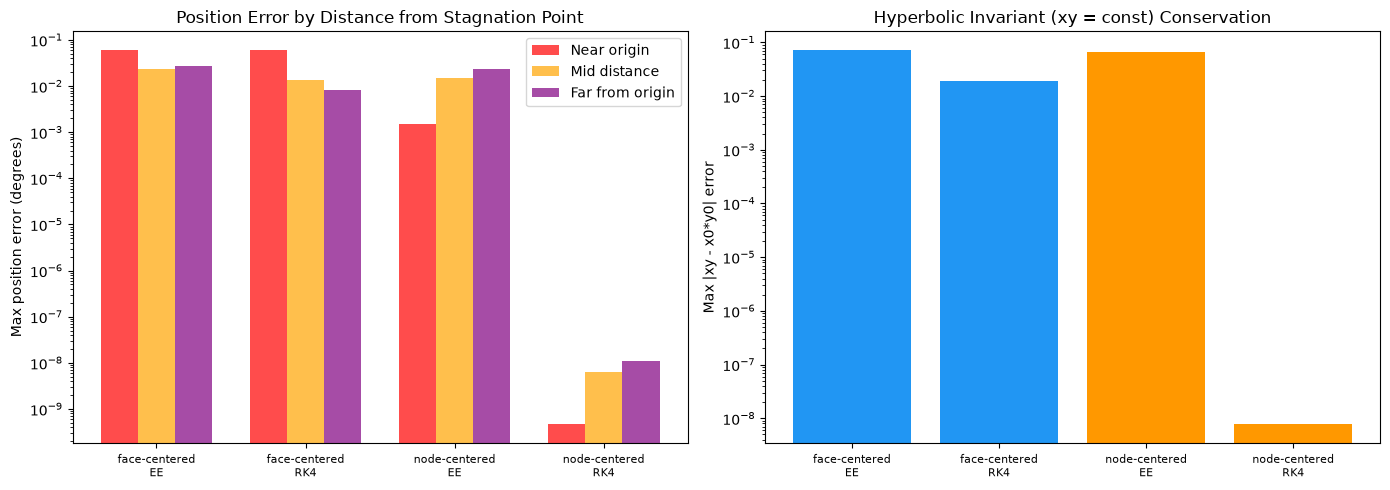

In [9]:
# Error bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = [f"{r['field_location']}\n{r['integrator']}" for r in results]
colors = ["#2196F3" if "face" in r["field_location"] else "#FF9800" for r in results]

# Position error by group
ax = axes[0]
x_pos = np.arange(len(results))
width = 0.25
ax.bar(x_pos - width, [r["max_err_near"] for r in results], width,
       label="Near origin", color="red", alpha=0.7)
ax.bar(x_pos, [r["max_err_mid"] for r in results], width,
       label="Mid distance", color="orange", alpha=0.7)
ax.bar(x_pos + width, [r["max_err_far"] for r in results], width,
       label="Far from origin", color="purple", alpha=0.7)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max position error (degrees)")
ax.set_title("Position Error by Distance from Stagnation Point")
ax.set_yscale("log")
ax.legend()

# Hyperbolic invariant error
ax = axes[1]
ax.bar(range(len(results)), [r["max_xy_invariant_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max |xy - x0*y0| error")
ax.set_title("Hyperbolic Invariant (xy = const) Conservation")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## 7. Trajectory Visualization

Overlay computed trajectories against the analytical hyperbolas.

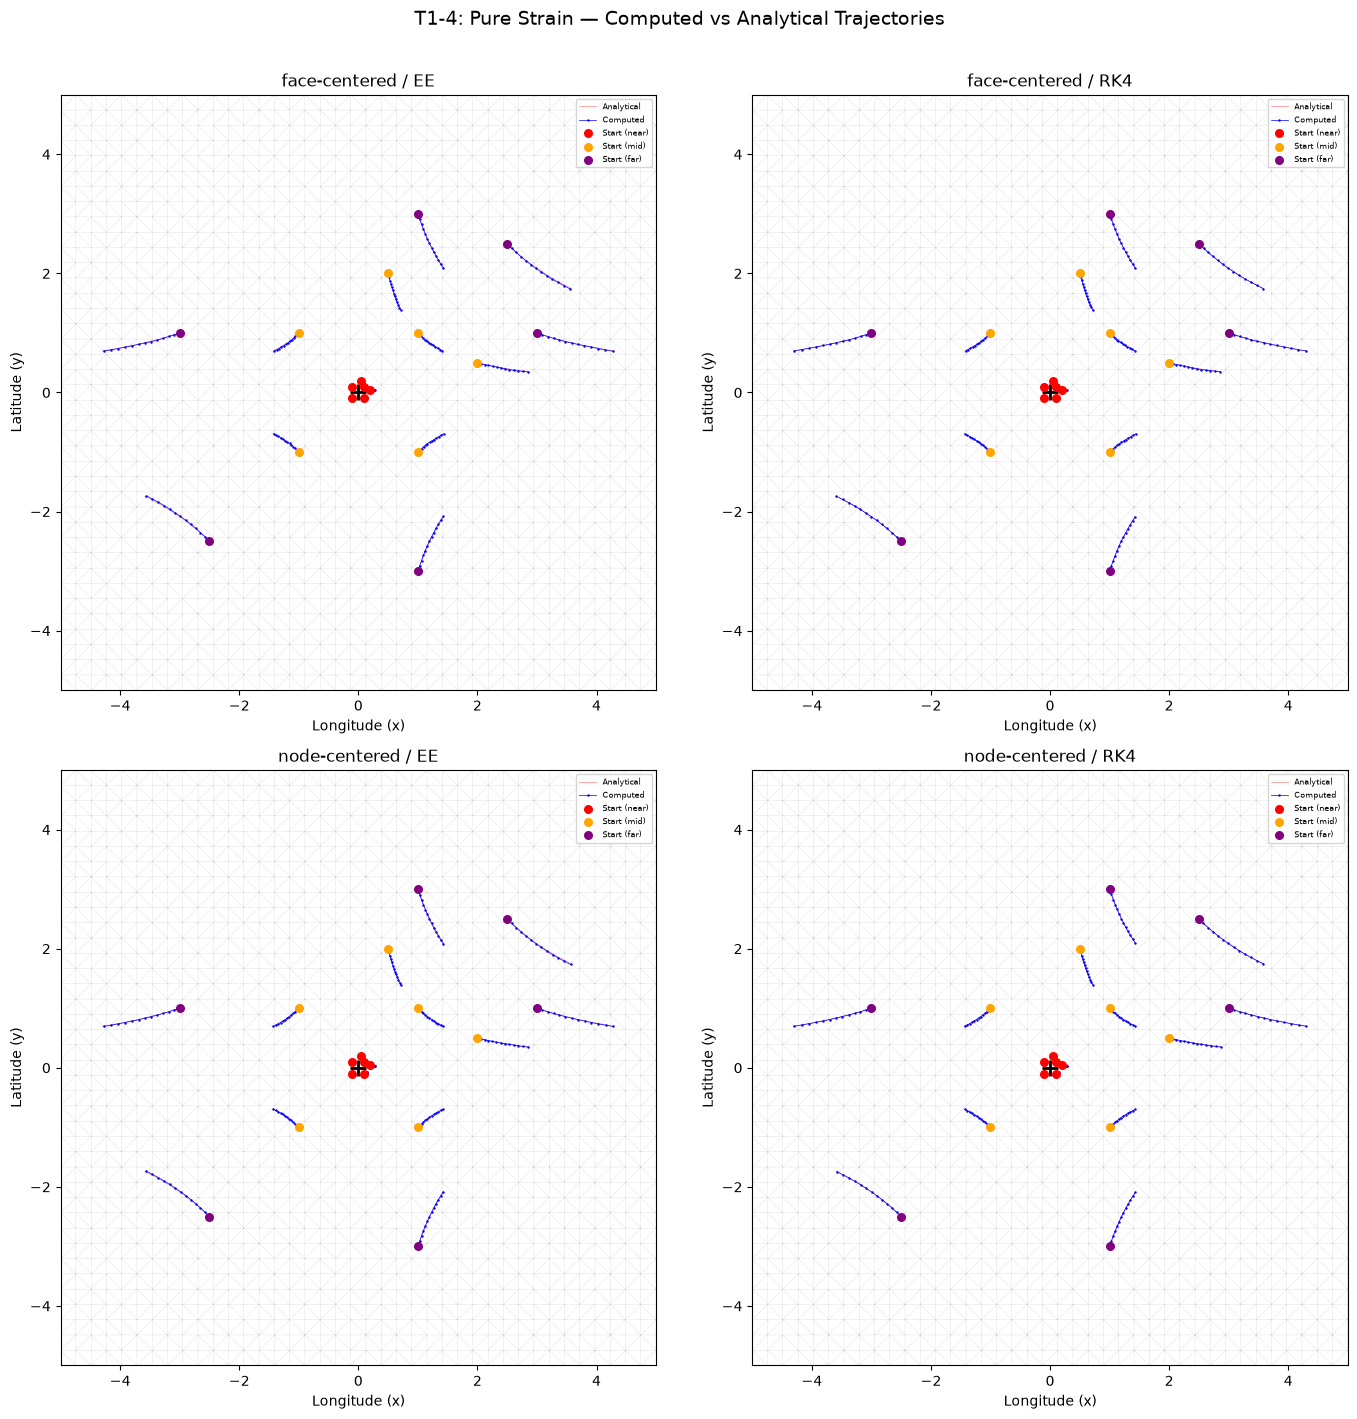

In [10]:
n_combos = len(output_files)
ncols = 2
nrows = math.ceil(n_combos / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 7 * nrows), squeeze=False)

t_fine = np.linspace(0, T_TOTAL_S, 500)

for idx, (label, out_path) in enumerate(output_files.items()):
    ax = axes[idx // ncols, idx % ncols]

    # Grid
    ax.triplot(triang, "k-", lw=0.2, alpha=0.2)

    # Analytical trajectories
    for i in range(N_PARTICLES):
        xa, ya = analytical_trajectory(p_lon0[i], p_lat0[i], EPSILON, t_fine)
        valid = (np.abs(xa) < HALF) & (np.abs(ya) < HALF)
        ax.plot(xa[valid], ya[valid], "r-", lw=0.6, alpha=0.4,
                label="Analytical" if i == 0 else None)

    # Computed trajectories from the parquet particle file
    traj_df = parcels.read_particlefile(out_path).sort("particle_id", "t")
    for p, pid in enumerate(traj_df["particle_id"].unique().sort()):
        traj = traj_df.filter(traj_df["particle_id"] == pid)
        lons = traj["x"].to_numpy()
        lats = traj["y"].to_numpy()
        ax.plot(lons, lats, "b.-", ms=1.5, lw=0.5,
                label="Computed" if p == 0 else None)

    # Color-coded start positions
    for group, color in colors_group.items():
        idx_g = [i for i, g in enumerate(particle_group) if g == group]
        ax.scatter(p_lon0[idx_g], p_lat0[idx_g], c=color, s=30, zorder=5,
                   label=f"Start ({group})")

    ax.plot(0, 0, "k+", ms=12, mew=2)
    ax.set_xlabel("Longitude (x)")
    ax.set_ylabel("Latitude (y)")
    ax.set_title(label)
    ax.legend(fontsize=6, loc="upper right")
    ax.set_aspect("equal")
    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)

for idx in range(n_combos, nrows * ncols):
    axes[idx // ncols, idx % ncols].set_visible(False)

fig.suptitle("T1-4: Pure Strain — Computed vs Analytical Trajectories",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8b. Convergence Study ($\Delta t$ refinement, node-centered)

On the node-centered grid the interpolant is exact for this linear field, so all error
comes from the time integrator. We refine $\Delta t$ and measure the slope.

We run a longer integration ($T = 2520$ s, $\approx 42$ min) using only the near-origin
particles ($|x_0| \leq 0.2$) so they stay safely inside the domain.
This accumulates enough RK4 truncation error to rise above the floating-point noise
floor. At $T = 360$ s with $\Delta t \leq 30$ s, RK4 errors on this linear ODE
are $\sim 10^{-7}$ — indistinguishable from roundoff.

## 8a. Diagnostic: Empirical Lag Measurement

Before running the convergence study, we empirically determine what time
`pset.lon` actually corresponds to after `execute()`. This tells us the
true lag to correct for.

In [11]:
# --- Diagnostic: empirically determine the lag ---
# For a single far particle in node-centered/RK4, compare pset.x against
# the analytical solution at various candidate times to find the best match.

fieldset_diag = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")

print(f"{'dt':>6s}  {'pset.x':>12s}  {'best_t':>8s}  {'lag':>8s}  {'T-dt':>8s}  {'T-2dt':>8s}")
print("-" * 70)

for dt_s in [120, 60, 30, 15, 5]:
    dt = np.timedelta64(dt_s, "s")
    x0_test = 3.0  # far particle

    pset = parcels.ParticleSet(fieldset_diag, x=[x0_test], y=[1.0])
    pset.execute(parcels.kernels.AdvectionRK4, runtime=T_TOTAL, dt=dt,
                 verbose_progress=False)

    lon_final = float(pset.x[0])

    # Search for the time that best matches pset.x
    t_candidates = np.arange(0, T_TOTAL_S + dt_s, 1.0)
    lon_candidates = x0_test * np.exp(EPSILON * t_candidates)
    best_idx = np.argmin(np.abs(lon_candidates - lon_final))
    best_t = t_candidates[best_idx]

    print(f"{dt_s:6d}  {lon_final:12.6f}  {best_t:8.1f}  "
          f"{T_TOTAL_S - best_t:8.1f}  {T_TOTAL_S - dt_s:8.1f}  {T_TOTAL_S - 2*dt_s:8.1f}")


    dt        pset.x    best_t       lag      T-dt     T-2dt
----------------------------------------------------------------------
   120      4.299986     360.0       0.0     240.0     120.0
    60      4.299988     360.0       0.0     300.0     240.0
    30      4.299989     360.0       0.0     330.0     300.0
    15      4.299988     360.0       0.0     345.0     330.0
     5      4.299989     360.0       0.0     355.0     350.0


In [12]:
# Convergence study: use a longer integration to push RK4 errors above
# roundoff noise. For the linear ODE dx/dt = eps*x, RK4 local truncation
# is O(dt^5) — at small dt this is sub-microsecond and lost in noise.
# We run for T_CONV = 3600s (1 hour) using only near-origin particles
# (max |x0| = 0.2) to stay in domain: 0.2*exp(0.001*3600) ~ 7.3 — note
# this WILL exit the domain. Use mid particles with max |x0| = 2 and
# T_CONV = 1800s: 2*exp(1.8) = 12 — also exits.
# Safest: use near particles (|x0| <= 0.2) with T_CONV = 3600s.
# 0.2*exp(3.6) = 7.3 — exits. Use T_CONV = 2520s: 0.2*exp(2.52) = 2.5 — safe.
# LCM must divide: use DT_VALUES that divide 2520.
# 2520 / 360 = 7, /180 = 14, /120 = 21, /60 = 42, /30 = 84, /15 = 168, /5 = 504 ✓

DT_VALUES = [360, 180, 120, 60, 30, 15, 5]
T_CONV_S = 2520.0
T_CONV = np.timedelta64(int(T_CONV_S), "s")

# Use only near-origin particles to stay well inside the domain
p_lon_conv = p_lon0[:n_near].copy()
p_lat_conv = p_lat0[:n_near].copy()

convergence_results = []

fieldset_node = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")

for integrator_label, integrator in time_integrators.items():
    for dt_s in DT_VALUES:
        dt = np.timedelta64(dt_s, "s")

        pset = parcels.ParticleSet(
            fieldset_node,
            pclass=Particle64,
            x=p_lon_conv.copy(),
            y=p_lat_conv.copy(),
        )

        pset.execute(
            integrator,
            runtime=T_CONV,
            dt=dt,
            verbose_progress=False,
        )

        # No lag correction needed: pset.x
        # is at T exactly (when T is divisible by dt).
        lon_exact, lat_exact = analytical_position(
            p_lon_conv, p_lat_conv, EPSILON, T_CONV_S)
        pos_err = np.sqrt((pset.x - lon_exact)**2 + (pset.y - lat_exact)**2)

        convergence_results.append({
            "integrator": integrator_label,
            "dt_s": dt_s,
            "max_error": np.max(pos_err),
            "mean_error": np.mean(pos_err),
        })

        print(f"{integrator_label:4s} | dt={dt_s:4d}s | max err = {np.max(pos_err):.4e}")

df_conv = pd.DataFrame(convergence_results)
df_conv

EE   | dt= 360s | max err = 7.6464e-01
EE   | dt= 180s | max err = 4.5627e-01
EE   | dt= 120s | max err = 3.2495e-01
EE   | dt=  60s | max err = 1.7431e-01
EE   | dt=  30s | max err = 9.0436e-02
EE   | dt=  15s | max err = 4.6083e-02
EE   | dt=   5s | max err = 1.5559e-02
RK4  | dt= 360s | max err = 6.5021e-04
RK4  | dt= 180s | max err = 4.7203e-05
RK4  | dt= 120s | max err = 9.8045e-06
RK4  | dt=  60s | max err = 6.3851e-07
RK4  | dt=  30s | max err = 4.3534e-08
RK4  | dt=  15s | max err = 2.2754e-09
RK4  | dt=   5s | max err = 4.1861e-10


,integrator,dt_s,max_error,mean_error
0,EE,360,7.646363e-01,4.142120e-01
1,EE,180,4.562714e-01,2.471614e-01
2,EE,120,3.249503e-01,1.760237e-01
3,EE,60,1.743131e-01,9.442373e-02
4,EE,30,9.043623e-02,4.898829e-02
5,EE,15,4.608308e-02,2.496265e-02
6,EE,5,1.555915e-02,8.428194e-03
7,RK4,360,6.502124e-04,3.522562e-04
8,RK4,180,4.720264e-05,2.557068e-05
9,RK4,120,9.804536e-06,5.307963e-06


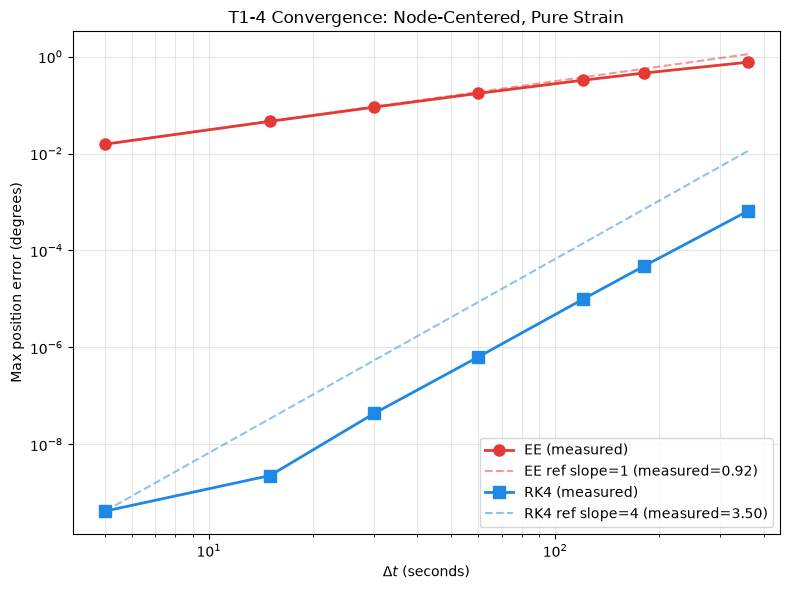

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

markers = {"EE": "o", "RK4": "s"}
colors_int = {"EE": "#E53935", "RK4": "#1E88E5"}
expected_orders = {"EE": 1, "RK4": 4}

for integrator_label in time_integrators:
    mask = df_conv["integrator"] == integrator_label
    dts = df_conv.loc[mask, "dt_s"].values.astype(float)
    errs = df_conv.loc[mask, "max_error"].values

    ax.loglog(dts, errs, f"{markers[integrator_label]}-",
              color=colors_int[integrator_label],
              label=f"{integrator_label} (measured)", ms=8, lw=2)

    if len(dts) >= 2 and np.all(errs > 0):
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
        p = expected_orders[integrator_label]
        ref_err = errs[-1] * (dts / dts[-1])**p
        ax.loglog(dts, ref_err, "--",
                  color=colors_int[integrator_label], alpha=0.5,
                  label=f"{integrator_label} ref slope={p} (measured={slope:.2f})")

ax.set_xlabel(r"$\Delta t$ (seconds)")
ax.set_ylabel("Max position error (degrees)")
ax.set_title(r"T1-4 Convergence: Node-Centered, Pure Strain")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Error Amplification Analysis

The exponential growth of the strain flow means that position errors are amplified over time.
We track how error grows with time for the node-centered / RK4 combination at the baseline dt.

INFO: Output files are stored in T1_4_error_growth.parquet


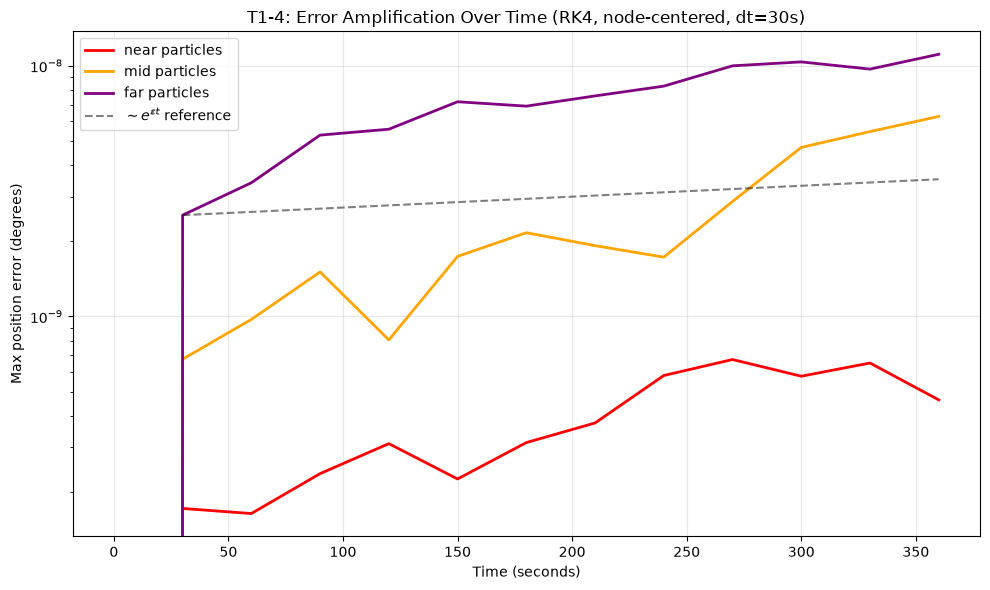

In [14]:
# Run with output at every step to track error growth
DT_TRACK = np.timedelta64(30, "s")
DT_TRACK_S = 30.0
out_track = "T1_4_error_growth.parquet"

fieldset_node2 = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")
pset = parcels.ParticleSet(
    fieldset_node2,
    pclass=Particle64,
    x=p_lon0.copy(),
    y=p_lat0.copy(),
)
pfile = parcels.ParticleFile(path=out_track, outputdt=DT_TRACK, mode="w")
pset.execute(
    parcels.kernels.AdvectionRK4,
    runtime=T_TOTAL,
    dt=DT_TRACK,
    output_file=pfile,
    verbose_progress=False,
)

# Read back and compute error at each output time
traj_df = parcels.read_particlefile(out_track, decode_times=False).sort("t", "particle_id")
t_all = traj_df["t"].to_numpy()
pid_all = traj_df["particle_id"].to_numpy()
t0 = t_all.min()

time_s = []
max_err_by_group = {"near": [], "mid": [], "far": []}

for t in np.unique(t_all):
    elapsed = float(t - t0)
    time_s.append(elapsed)

    at_t = t_all == t
    assert np.array_equal(pid_all[at_t], np.arange(N_PARTICLES)), "expected every particle at every output time"
    lons = traj_df["x"].to_numpy()[at_t]
    lats = traj_df["y"].to_numpy()[at_t]

    lon_exact, lat_exact = analytical_position(p_lon0, p_lat0, EPSILON, elapsed)
    pos_err = np.sqrt((lons - lon_exact)**2 + (lats - lat_exact)**2)

    for group, (start, end) in [("near", (0, n_near)),
                                 ("mid", (n_near, n_near + n_mid)),
                                 ("far", (n_near + n_mid, N_PARTICLES))]:
        max_err_by_group[group].append(np.max(pos_err[start:end]))


fig, ax = plt.subplots(figsize=(10, 6))
for group, color in colors_group.items():
    ax.semilogy(time_s, max_err_by_group[group], "-", color=color,
                label=f"{group} particles", lw=2)

# Reference exponential growth
t_ref = np.array(time_s)
valid = t_ref > 0
if np.any(valid) and len(max_err_by_group["far"]) > 1:
    err0 = max_err_by_group["far"][1] if max_err_by_group["far"][1] > 0 else 1e-15
    ref_growth = err0 * np.exp(EPSILON * (t_ref[valid] - t_ref[1]))
    ax.semilogy(t_ref[valid], ref_growth, "k--", alpha=0.5,
                label=rf"$\sim e^{{\varepsilon t}}$ reference")

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Max position error (degrees)")
ax.set_title("T1-4: Error Amplification Over Time (RK4, node-centered, dt=30s)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

os.remove(out_track)

## 10. Verification Assertions

### Node-centered checks
With exact interpolation of the linear field, all error is from the ODE integrator:
1. **Convergence order:** measured slope should be within 0.5 of the expected order
2. **RK4 at fine dt:** error should be small (accounting for exponential amplification)

### Face-centered checks
Piecewise-constant interpolation introduces spatial error, so we only check that
the simulation completes and particles stay within a reasonable bound.

### Hyperbolic invariant
The product $x \cdot y$ should be conserved. For the node-centered / RK4 combination
at fine dt, the invariant error should be very small.

In [15]:
all_pass = True

# --- Check 1: Convergence orders (node-centered) ---
print("=== Convergence Order Checks (node-centered) ===")
for integrator_label in time_integrators:
    mask = df_conv["integrator"] == integrator_label
    dts = df_conv.loc[mask, "dt_s"].values.astype(float)
    errs = df_conv.loc[mask, "max_error"].values

    if len(dts) >= 2 and np.all(errs > 0):
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
        expected = expected_orders[integrator_label]
        ok = abs(slope - expected) < 0.5
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {integrator_label}: measured slope = {slope:.2f}, "
              f"expected ~ {expected}")
    else:
        print(f"  [SKIP] {integrator_label}: insufficient data for slope")

# --- Check 2: RK4 absolute accuracy at finest dt ---
print("\n=== RK4 Absolute Accuracy (node-centered, finest dt) ===")
rk4_finest = df_conv.loc[
    (df_conv["integrator"] == "RK4") & (df_conv["dt_s"] == min(DT_VALUES)),
    "max_error"
].values
if len(rk4_finest) > 0:
    err = rk4_finest[0]
    # Looser threshold than rotation: exponential amplification increases absolute error
    threshold = 1e-4
    ok = err < threshold
    status = "PASS" if ok else "FAIL"
    if not ok:
        all_pass = False
    print(f"  [{status}] RK4 max error at dt={min(DT_VALUES)}s: {err:.4e} "
          f"(threshold {threshold:.0e})")

# --- Check 3: Face-centered runs complete with bounded error ---
print("\n=== Face-Centered Sanity Checks ===")
for r in results:
    if r["field_location"] == "face-centered":
        ok = r["max_position_error"] < 5.0
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {r['field_location']} / {r['integrator']}: "
              f"max err = {r['max_position_error']:.4e}")

# --- Check 4: Error scales with distance from stagnation point ---
print("\n=== Error Scaling with Distance (node-centered / RK4) ===")
for r in results:
    if r["field_location"] == "node-centered" and r["integrator"] == "RK4":
        # Far particles should have larger errors than near particles
        ok = r["max_err_far"] >= r["max_err_near"]
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] far err ({r['max_err_far']:.4e}) >= "
              f"near err ({r['max_err_near']:.4e})")

print()
if all_pass:
    print("T1-4 PASSED: All checks within tolerance.")
else:
    raise AssertionError(
        "T1-4 FAILED: One or more checks exceeded tolerance. "
        "Review convergence plots above."
    )

=== Convergence Order Checks (node-centered) ===
  [PASS] EE: measured slope = 0.92, expected ~ 1
  [PASS] RK4: measured slope = 3.50, expected ~ 4

=== RK4 Absolute Accuracy (node-centered, finest dt) ===
  [PASS] RK4 max error at dt=5s: 4.1861e-10 (threshold 1e-04)

=== Face-Centered Sanity Checks ===
  [PASS] face-centered / EE: max err = 6.0566e-02
  [PASS] face-centered / RK4: max err = 6.0566e-02

=== Error Scaling with Distance (node-centered / RK4) ===
  [PASS] far err (1.1102e-08) >= near err (4.6450e-10)

T1-4 PASSED: All checks within tolerance.


## 11. Cleanup

In [16]:
for out_path in output_files.values():
    if os.path.exists(out_path):
        os.remove(out_path)
print("Temporary output cleaned up.")

Temporary output cleaned up.
